# 05 Collaborative filtering

De opdracht noemt *matrix factorization* en *k-nearest neighbors*. Collaborative filtering gebruikt de **keuzes van andere
studenten**: als studenten die dezelfde dingen goed vonden als jij ook boek X goed vonden, dan past X waarschijnlijk bij jou.

In [1]:
import sys
from pathlib import Path

# Make the project package importable, also without "pip install -e ."
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from reading_coach import config

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
from reading_coach.collaborative import ItemKNN, SVDRecommender, user_item_matrix
from reading_coach.data_cleaning import load_processed

materials, students, interactions = load_processed()
codes = materials["catalog_code"].tolist()
titles = materials.set_index("catalog_code")["title"]

## 1. Van interacties naar een voorkeurscore
Niet elke student geeft een cijfer (beoordeling ontbreekt soms). Ik maak een score van 1 tot 5 uit het soort interactie en
middel die met de beoordeling als die er is. Hoeveel elk soort interactie waard is, staat niet in de code: dat is het
gemiddelde cijfer dat studenten gaven bij dat soort interactie.

In [3]:
from reading_coach.vocabulary import learn_interaction_scores

print(learn_interaction_scores(interactions))
interactions.groupby("interaction")[["rating", "preference_score", "read_pct"]].mean().round(2)

{'opgeslagen': 4.0, 'afgewezen': 1.955223880597015, 'gelezen': 4.091891891891892, 'niet_afgemaakt': 2.642578125, 'bekeken': 3.0, 'geliket': 5.0}


,rating,preference_score,read_pct
interaction,,,
afgewezen,1.96,1.96,0.21
bekeken,3.00,3.00,0.56
gelezen,4.09,4.09,0.87
geliket,5.00,5.00,0.95
niet_afgemaakt,2.64,2.64,0.41
opgeslagen,4.00,4.00,0.86


## 2. De student x materiaal matrix

Matrix (100, 275), 5.2% gevuld (sparsity 94.8%)


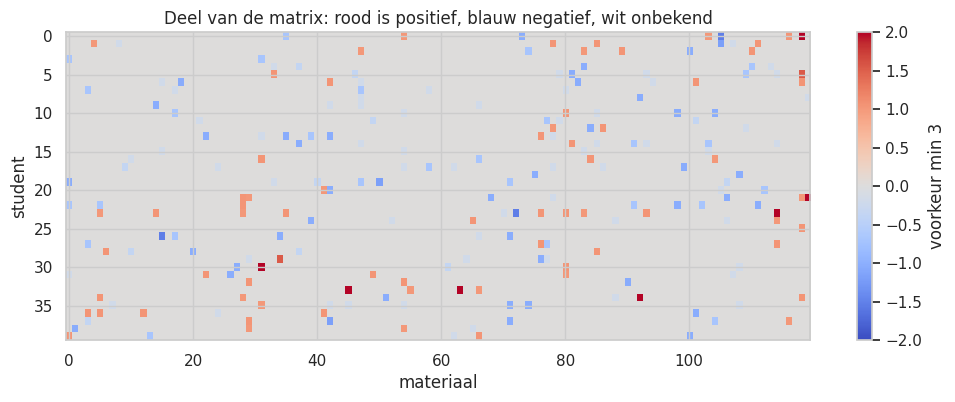

In [4]:
matrix = user_item_matrix(interactions, codes, students["student_id"].tolist())
filled = (matrix != 0).to_numpy().mean()
print(f"Matrix {matrix.shape}, {filled:.1%} gevuld (sparsity {1 - filled:.1%})")
plt.figure(figsize=(12, 4))
plt.imshow(matrix.iloc[:40, :120].to_numpy(), aspect="auto", cmap="coolwarm", vmin=-2, vmax=2)
plt.colorbar(label="voorkeur min 3")
plt.xlabel("materiaal"); plt.ylabel("student")
plt.title("Deel van de matrix: rood is positief, blauw negatief, wit onbekend")
plt.show()

## 3. Item KNN
Twee materialen lijken op elkaar als dezelfde studenten ze op dezelfde manier waarderen. We houden per materiaal de 20 sterkste buren over.

In [5]:
knn = ItemKNN(k=20).fit(matrix)
student_id = "S001"
own = interactions.query("student_id == @student_id")
history = dict(zip(own["catalog_code"], own["preference_score"]))
scores = pd.Series(knn.scores(history), index=codes).drop(index=list(history))
pd.DataFrame({"title": titles[scores.nlargest(5).index].to_numpy(), "knn_score": scores.nlargest(5).round(3).to_numpy()})

,title,knn_score
0,"Moeder worden, moeder zijn",2.0
1,Shoot-out,2.0
2,Heartstopper 3,2.0
3,Yasmin,2.0
4,De blauwe stilte,2.0


## 4. Matrix factorisatie met SVD
SVD vat de matrix samen in een paar *smaakdimensies*. Een nieuwe student kunnen we op die dimensies projecteren (*fold in*), zonder opnieuw te trainen.

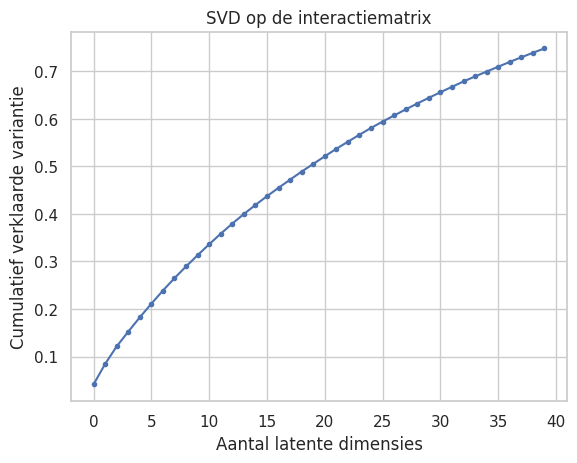

,title,svd_score
0,Biodiversiteit in Nederland: de stand van zaken,0.410
1,Imke,0.360
2,Terug naar school,0.333
3,De vrolijke advocaat,0.320
4,Zweer het me,0.319


In [6]:
from sklearn.decomposition import TruncatedSVD

explained = TruncatedSVD(n_components=40, random_state=config.RANDOM_STATE).fit(matrix.to_numpy()).explained_variance_ratio_
plt.plot(np.cumsum(explained), marker=".")
plt.xlabel("Aantal latente dimensies"); plt.ylabel("Cumulatief verklaarde variantie")
plt.title("SVD op de interactiematrix")
plt.show()

svd = SVDRecommender(n_components=12).fit(matrix)
scores = pd.Series(svd.scores(history), index=codes).drop(index=list(history))
pd.DataFrame({"title": titles[scores.nlargest(5).index].to_numpy(), "svd_score": scores.nlargest(5).round(3).to_numpy()})

## 5. Eerlijk evalueren
We trainen op de oudere 75% van de interacties per student en testen op de nieuwste 25%. Zo voorspellen we de toekomst, net als in de echte app.

In [7]:
from reading_coach.evaluation import evaluate_rankings, make_scorers, temporal_split
from reading_coach.hybrid import HybridRecommender

train, test = temporal_split(interactions)
model = HybridRecommender().fit(materials, students, train)
scorers = make_scorers(model, train, students)
selection = ["Random", "Popularity", "Item KNN", "Matrix factorisation (SVD)"]
evaluate_rankings({name: scorers[name] for name in selection}, model, students, train, test)

,precision@5,recall@5,ndcg@5,hitrate@5,auc_test_interactions,auc_per_student
method,,,,,,
Random,0.010,0.021,0.017,0.037,0.499,0.484
Popularity,0.047,0.132,0.121,0.235,0.637,0.649
Item KNN,0.007,0.014,0.009,0.037,0.535,0.536
Matrix factorisation (SVD),0.032,0.110,0.082,0.160,0.612,0.584


## Conclusie

* De matrix is voor bijna 95% leeg: elke student heeft maar 20 van de 275 materialen gezien. Collaborative filtering
  heeft dan weinig houvast en scoort hier zelfs slechter dan simpelweg de populairste materialen aanraden.
* Een nieuwe student heeft helemaal geen geschiedenis (*cold start*): collaborative filtering kan dan niets.
* Toch bevat het een signaal dat de inhoud niet heeft (smaak van vergelijkbare studenten). Daarom gebruiken we de KNN
  score als **een van de kenmerken** in het hybride model (notebook 06) in plaats van als los model.